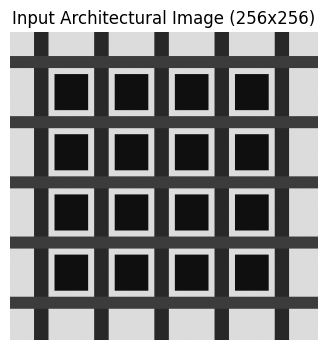

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.signal as signal
import tensorflow as tf
from tensorflow.keras import layers, models

# Create a crisp architectural grid image (256x256) with strong horizontal/vertical edges & contrast
img = np.ones((256, 256), dtype=np.float32) * 220.0  # Light concrete background

# Draw vertical pillars (dark grey)
for x in range(20, 240, 50):
    img[:, x:x+12] = 40.0

# Draw horizontal beams (medium-dark grey)
for y in range(20, 240, 50):
    img[y:y+10, :] = 60.0

# Add high-contrast window shadows inside the grid cells
for y in range(35, 210, 50):
    for x in range(37, 210, 50):
        img[y:y+30, x:x+28] = 15.0

plt.figure(figsize=(4, 4))
plt.imshow(img, cmap='gray', vmin=0, vmax=255)
plt.title("Input Architectural Image (256x256)")
plt.axis('off')
plt.show()

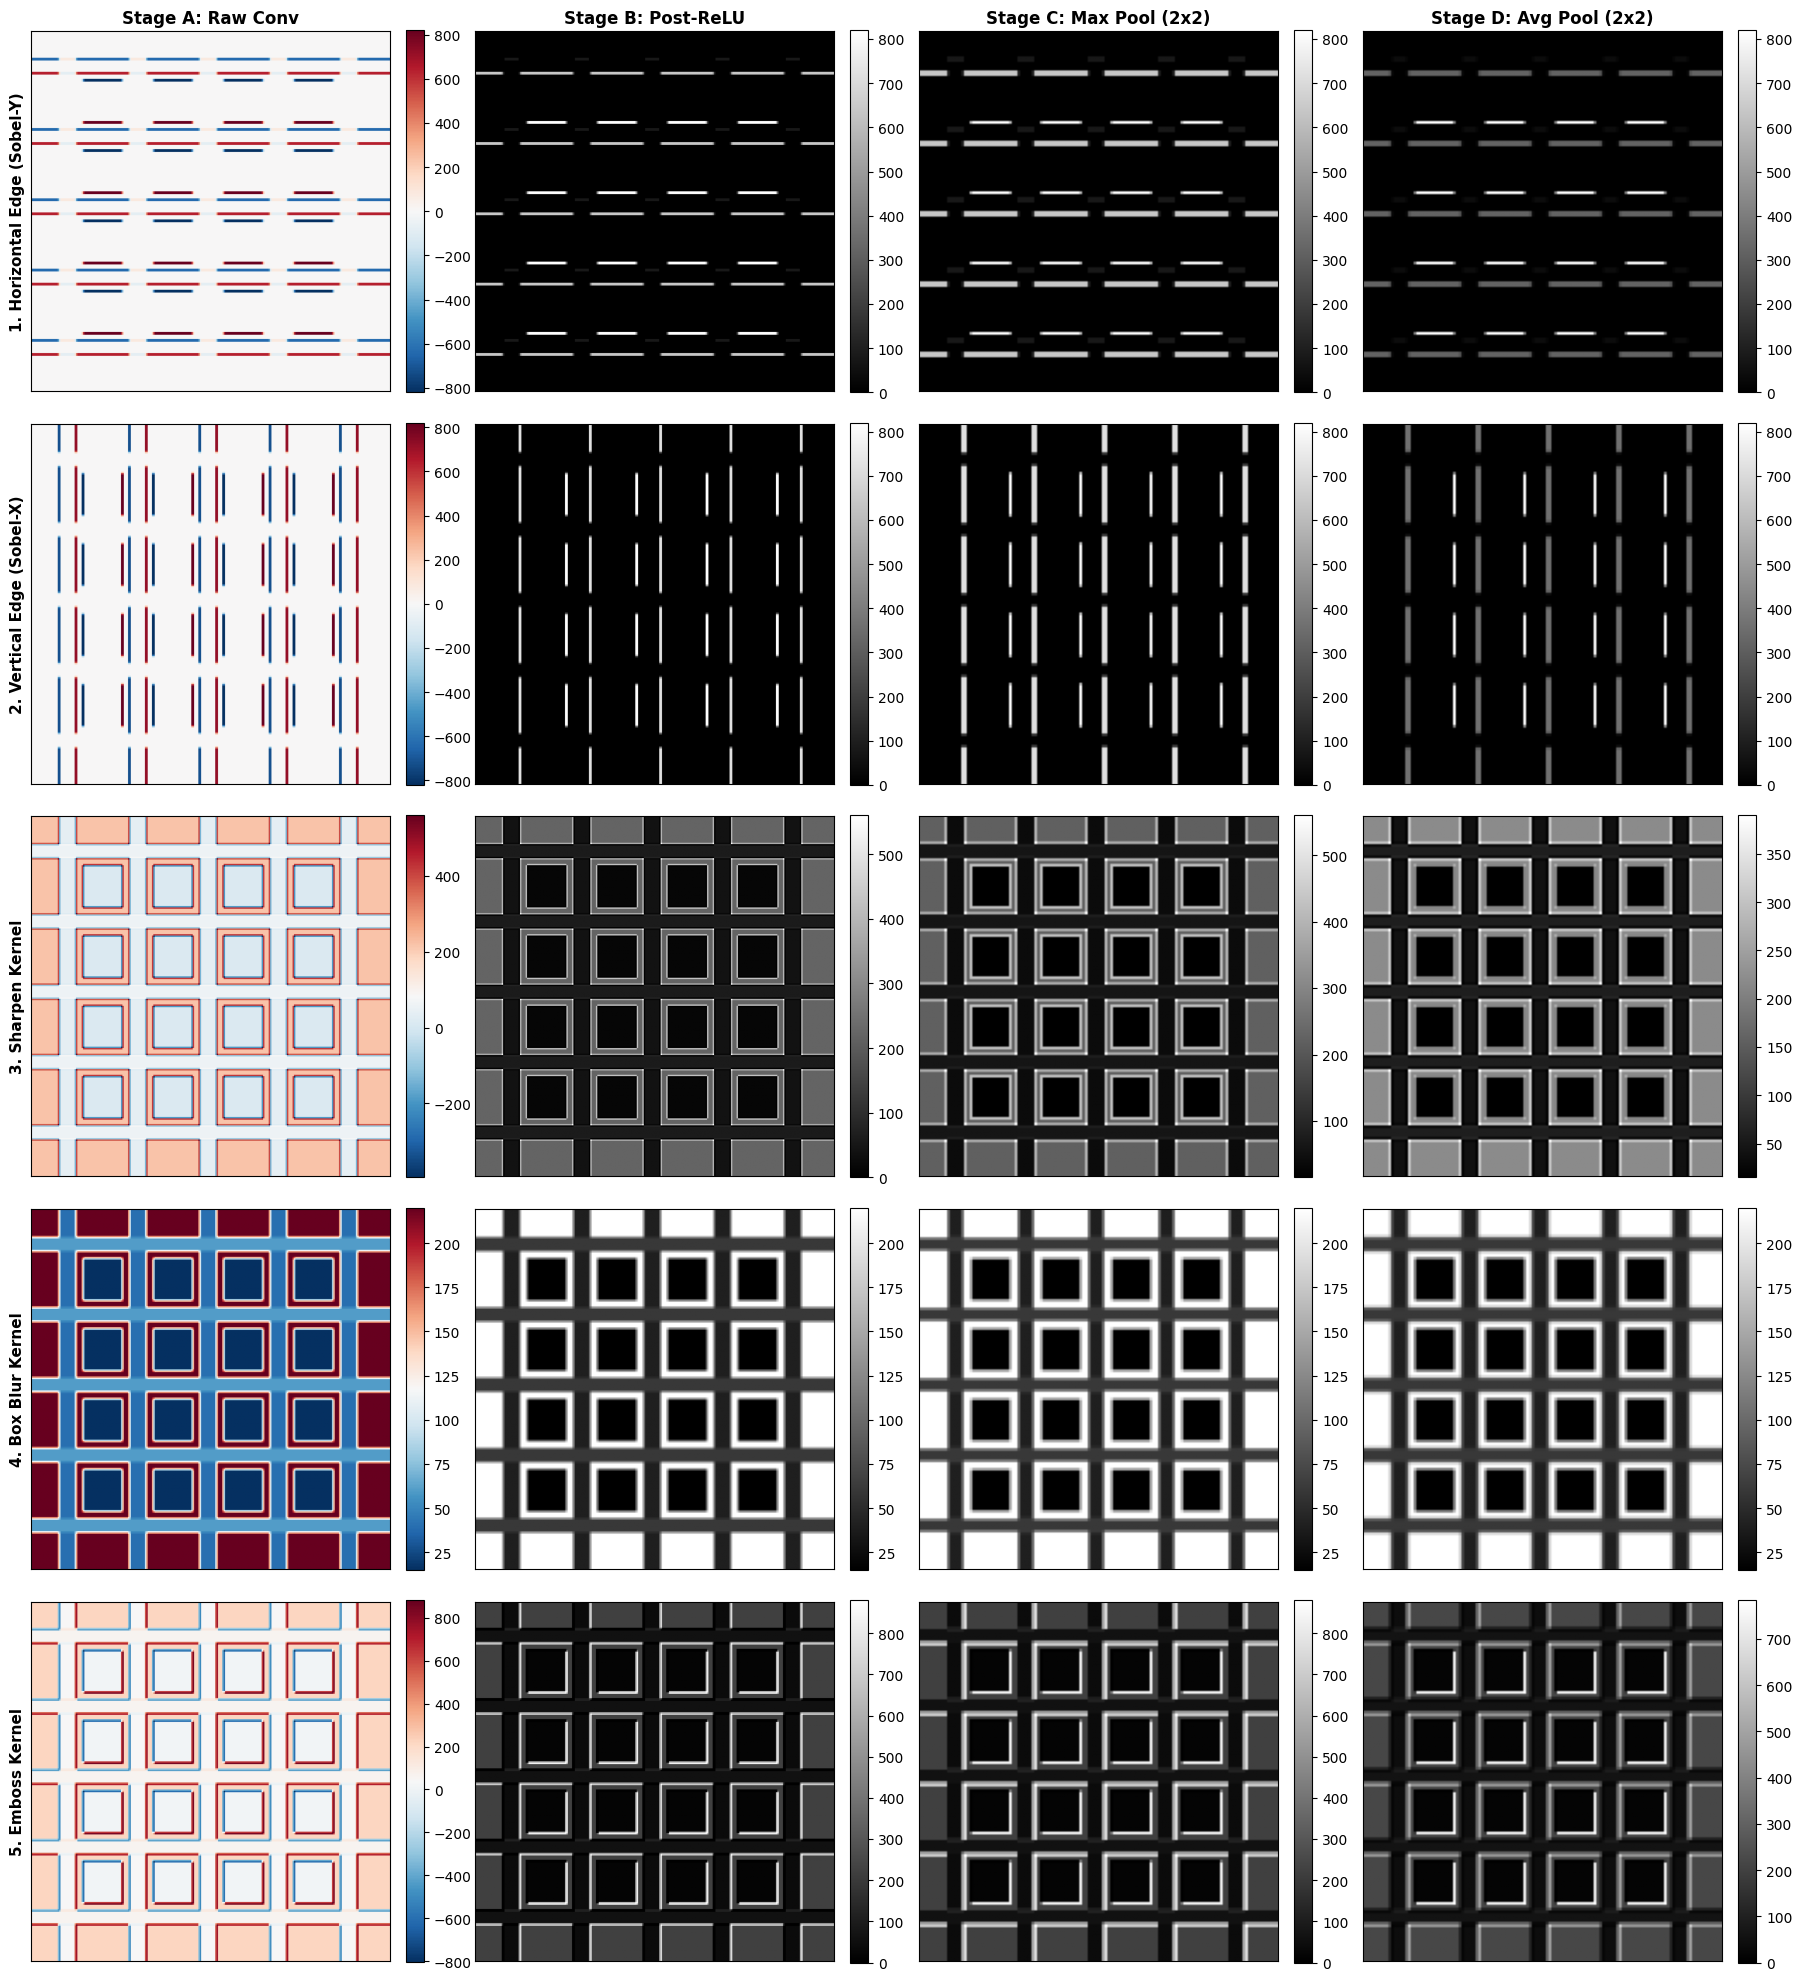

In [2]:
# 1. Define the Five Custom 3x3 Kernels
kernels = {
    "1. Horizontal Edge (Sobel-Y)": np.array([[-1, -2, -1],
                                              [ 0,  0,  0],
                                              [ 1,  2,  1]], dtype=np.float32),

    "2. Vertical Edge (Sobel-X)":   np.array([[-1,  0,  1],
                                              [-2,  0,  2],
                                              [-1,  0,  1]], dtype=np.float32),

    "3. Sharpen Kernel":            np.array([[ 0, -1,  0],
                                              [-1,  5, -1],
                                              [ 0, -1,  0]], dtype=np.float32),

    "4. Box Blur Kernel":           np.ones((3, 3), dtype=np.float32) / 9.0,

    "5. Emboss Kernel":             np.array([[-2, -1,  0],
                                              [-1,  1,  1],
                                              [ 0,  1,  2]], dtype=np.float32)
}

# Helper functions for Pooling (2x2, stride 2)
def max_pool_2x2(feature_map):
    h, w = feature_map.shape
    return feature_map[:h//2*2, :w//2*2].reshape(h//2, 2, w//2, 2).max(axis=(1, 3))

def avg_pool_2x2(feature_map):
    h, w = feature_map.shape
    return feature_map[:h//2*2, :w//2*2].reshape(h//2, 2, w//2, 2).mean(axis=(1, 3))

# 2. Plot Unified 5x4 Visualization Grid
fig, axes = plt.subplots(5, 4, figsize=(18, 20))
stages = ["Stage A: Raw Conv", "Stage B: Post-ReLU", "Stage C: Max Pool (2x2)", "Stage D: Avg Pool (2x2)"]

for row_idx, (name, kernel) in enumerate(kernels.items()):
    # Stage A: Raw Convolution (using cross-correlation / valid convolution)
    stage_a = signal.correlate2d(img, kernel, mode='same', boundary='symm')

    # Stage B: Post-ReLU Activation
    stage_b = np.maximum(0, stage_a)

    # Stage C: Max Pooling (2x2, stride 2)
    stage_c = max_pool_2x2(stage_b)

    # Stage D: Average Pooling (2x2, stride 2)
    stage_d = avg_pool_2x2(stage_b)

    outputs = [stage_a, stage_b, stage_c, stage_d]

    for col_idx, out_map in enumerate(outputs):
        ax = axes[row_idx, col_idx]
        # Use diverging colormap for Stage A (shows negative values clearly), gray for B-D
        cmap_choice = 'RdBu_r' if col_idx == 0 else 'gray'
        im = ax.imshow(out_map, cmap=cmap_choice)
        plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

        if row_idx == 0:
            ax.set_title(stages[col_idx], fontsize=12, fontweight='bold')
        if col_idx == 0:
            ax.set_ylabel(name, fontsize=11, fontweight='bold')
        ax.set_xticks([])
        ax.set_yticks([])

plt.tight_layout()
plt.savefig("CNN_5x4_Visualization_Grid.png", dpi=300)
plt.show()

In [3]:
def build_model_a():
    model = models.Sequential([
        layers.Input(shape=(32, 32, 3)),
        layers.Conv2D(5, kernel_size=(3, 3), activation='relu', name='conv1'),
        layers.MaxPooling2D(pool_size=(2, 2), strides=2),
        layers.Conv2D(10, kernel_size=(3, 3), activation='relu', name='conv2'),
        layers.MaxPooling2D(pool_size=(2, 2), strides=2),
        layers.GlobalAveragePooling2D(),
        layers.Dense(10, activation='softmax', name='output_dense')
    ], name="Model_A_Standard")
    return model

def build_model_b():
    model = models.Sequential([
        layers.Input(shape=(32, 32, 3)),
        layers.Conv2D(5, kernel_size=(5, 5), activation='relu', name='conv1'),
        layers.AveragePooling2D(pool_size=(2, 2), strides=2),
        layers.Conv2D(10, kernel_size=(5, 5), activation='relu', name='conv2'),
        layers.AveragePooling2D(pool_size=(2, 2), strides=2),
        layers.GlobalAveragePooling2D(),
        layers.Dense(10, activation='softmax', name='output_dense')
    ], name="Model_B_Large_Kernel")
    return model

model_a = build_model_a()
model_b = build_model_b()

print("=== MODEL A SUMMARY ===")
model_a.summary()
print("\n=== MODEL B SUMMARY ===")
model_b.summary()

=== MODEL A SUMMARY ===


Model: "Model_A_Standard"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1 (Conv2D)                  │ (None, 30, 30, 5)      │           140 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 5)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 13, 13, 10)     │           460 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 10)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 10)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_dense (Dense)            │ (None, 10)             │           110 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 710 (2.77 KB)

 Trainable params: 710 (2.77 KB)

 Non-trainable params: 0 (0.00 B)

... (2 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1 (Conv2D)                  │ (None, 28, 28, 5)      │           380 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d               │ (None, 14, 14, 5)      │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 10, 10, 10)     │         1,260 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_1             │ (None, 5, 5, 10)       │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 10)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_dense (Dense)            │ (None, 10)             │           110 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,750 (6.84 KB)

 Trainable params: 1,750 (6.84 KB)

 Non-trainable params: 0 (0.00 B)